## Simulação do sinal de um voxel do fígado ao longo de 7 ecos (5% FF).
T2* da água e das gorduras são fixos, definir variável fatPercent para %FF.

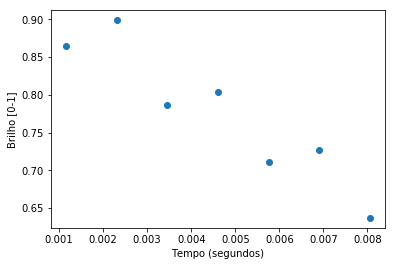

In [211]:
import numpy as np
import matplotlib.pyplot as plt

fatPercent = 0.05

t = [0.0011515,  \
     0.0011515*2,\
     0.0011515*3,\
     0.0011515*4,\
     0.0011515*5,\
     0.0011515*6,\
     0.0011515*7]

rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water

t2star = [0.030,\
          0.040,\
          0.051,\
          0.052,\
          0.062,\
          0.083,\
          0.023]

Fppmn = [5.3,\
         4.2,\
         2.75,\
         2.1,\
         1.3,\
         0.9,\
         4.7]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
t2star = np.array(t2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


    for n in counter:
        for index,TE in enumerate(t):
            S[n,index] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal = np.absolute(Sfinal) #descobrir o erro no np.absolute
plt.plot(t, Sfinal,'o')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()


## Observação do efeito do T2* da água na intensidade do sinal, %FF fixa 
(pontos 2, 4, 5, 7, contra aumento no T2* da água). Percebe-se aumento no sinal, em especial nos pontos mais tardios no tempo)

[0.69482104421244706, 0.70544273602217544, 0.71119060190317196, 0.71479309583614892]


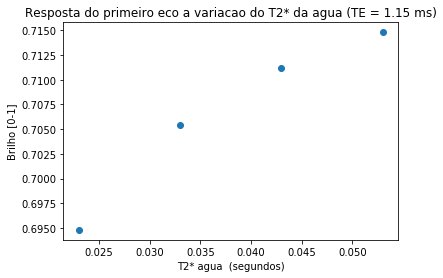

[0.646468936830498, 0.67657207491966453, 0.69324508294810017, 0.7038333122393633]


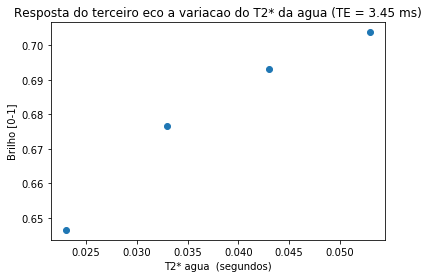

[0.58637788387735068, 0.6325889383879133, 0.65878364522783095, 0.67563868686408457]


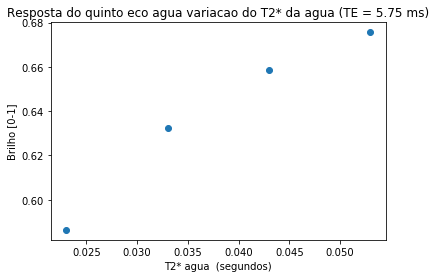

[0.52005661063778275, 0.57832536079133012, 0.61212756824047188, 0.63416507318037707]


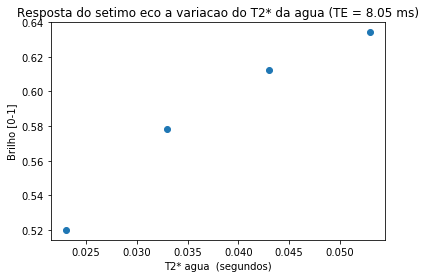

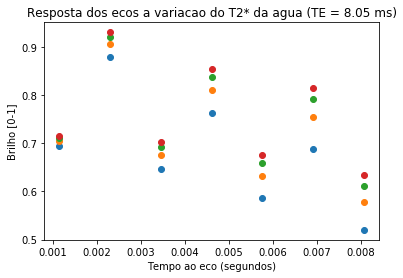

In [24]:
import numpy as np
import matplotlib.pyplot as plt

t = [0.0011515,  \
     0.0011515*2,\
     0.0011515*3,\
     0.0011515*4,\
     0.0011515*5,\
     0.0011515*6,\
     0.0011515*7]

fatPercent = 0.15

rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water

t2star = [0.030,\
          0.040,\
          0.051,\
          0.052,\
          0.062,\
          0.083]

t2starW = [0.023, 0.033, 0.043, 0.053]

Fppmn = [5.3,\
         4.2,\
         2.75,\
         2.1,\
         1.3,\
         0.9,\
         4.7]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
t2star = np.array(t2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Ssum= (7)
Ssum=np.zeros(Ssum,dtype='complex')
Sfinal = (4,7)
Sfinal = np.zeros(Sfinal)

for ind,t2w in enumerate(t2starW):
    for n in counter:
        for index,TE in enumerate(t):
            S[n,index] = rho[n]*np.exp(-TE/t2w)*np.exp(2.0*np.pi*1j*freq[n]*TE)         

    Ssum = np.sum(S, axis=0)
    Ssum = np.absolute(Ssum)
    #plt.xlabel('Tempo (segundos)')
    #plt.ylabel('Brilho [0-1]')
    #plt.show()
    Sfinal[ind,:] = Ssum

St = [Sfinal[0,0],Sfinal[1,0],Sfinal[2,0],Sfinal[3,0]]    
print (St)
plt.plot(t2starW, St,'o')
plt.title('Resposta do primeiro eco a variacao do T2* da agua (TE = 1.15 ms)')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()

St = [Sfinal[0,2],Sfinal[1,2],Sfinal[2,2],Sfinal[3,2]]    
print (St)
plt.plot(t2starW, St,'o')
plt.title('Resposta do terceiro eco a variacao do T2* da agua (TE = 3.45 ms)')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()

St = [Sfinal[0,4],Sfinal[1,4],Sfinal[2,4],Sfinal[3,4]]    
print (St)
plt.plot(t2starW, St,'o')
plt.title('Resposta do quinto eco agua variacao do T2* da agua (TE = 5.75 ms)')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()

St = [Sfinal[0,6],Sfinal[1,6],Sfinal[2,6],Sfinal[3,6]]    
print (St)
plt.plot(t2starW, St,'o')
plt.title('Resposta do setimo eco a variacao do T2* da agua (TE = 8.05 ms)')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()


plt.plot(t, Sfinal[0,:],'o')
plt.plot(t, Sfinal[1,:],'o')
plt.plot(t, Sfinal[2,:],'o')
plt.plot(t, Sfinal[3,:],'o')
plt.title('Resposta dos ecos a variacao do T2* da agua (TE = 8.05 ms)')
plt.xlabel('Tempo ao eco (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()


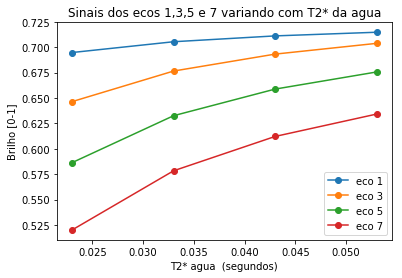

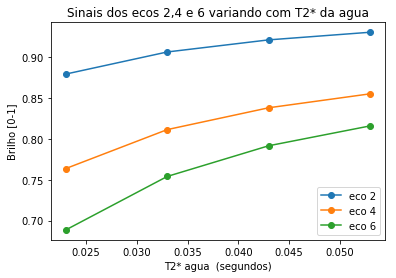

In [26]:
St1 = [Sfinal[0,0],Sfinal[1,0],Sfinal[2,0],Sfinal[3,0]]
St2 = [Sfinal[0,1],Sfinal[1,1],Sfinal[2,1],Sfinal[3,1]]
St3 = [Sfinal[0,2],Sfinal[1,2],Sfinal[2,2],Sfinal[3,2]]    
St6 = [Sfinal[0,5],Sfinal[1,5],Sfinal[2,5],Sfinal[3,5]]    
St5 = [Sfinal[0,4],Sfinal[1,4],Sfinal[2,4],Sfinal[3,4]]    
St4 = [Sfinal[0,3],Sfinal[1,3],Sfinal[2,3],Sfinal[3,3]]    
St7 = [Sfinal[0,6],Sfinal[1,6],Sfinal[2,6],Sfinal[3,6]]

plt.plot(t2starW, St1,'o-', label = "eco 1")
plt.plot(t2starW, St3,'o-', label = "eco 3")
plt.plot(t2starW, St5,'o-', label = "eco 5")
plt.plot(t2starW, St7,'o-', label = "eco 7")
plt.title('Sinais dos ecos 1,3,5 e 7 variando com T2* da agua')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(loc='best')
plt.show()

plt.plot(t2starW, St2,'o-', label = "eco 2")
plt.plot(t2starW, St4,'o-', label = "eco 4")
plt.plot(t2starW, St6,'o-', label = "eco 6")

plt.title('Sinais dos ecos 2,4 e 6 variando com T2* da agua')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(loc='best')
plt.show()